# ЛР-3 «SGD и его модификации»

Реализация SGD и его модификаций для задачи многомерной линейной/полиномиальной регрессии, сравнение со стандартными реализациями
из `torch.optim`. Расширения:

- **Extension-1.** **Lion** — оптимизатор без вторых моментов.
- **Extension-2.** Постановка soft-margin SVM как задачи выпуклой оптимизации
- **Extension-3.** Три способа вычисления градиента — численное диф. (центр. разности),
  forward-mode autodiff на дуальных числах, reverse-mode через `torch.autograd`.


In [1]:
import os
import sys

sys.path.insert(0, os.path.abspath('src'))
import warnings

warnings.filterwarnings('ignore')  

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from data.real import load_california
from data.synthetic import make_linear_regression
from models.linear import LinearRegressionModel
from models.poly import PolynomialRegression
from optimizers import SGD, AdaGrad, Adam, Lion, Momentum, Nesterov, RMSProp
from plotting import figure, plot_contours
from regularizers import L1, L2, ElasticNet, NoReg
from schedulers import ConstantLR, CosineWarmup, ExpDecay, InvDecay, StepDecay
from training.torch_wrappers import (
    TorchAdaGrad,
    TorchAdam,
    TorchAdamW,
    TorchMomentum,
    TorchNesterov,
    TorchRMSProp,
    TorchSGD,
)
from training.trainer import train

np.random.seed(0)
torch.manual_seed(0)
plt.rcParams['figure.figsize'] = (8, 5)

## 1. Данные

Используются два датасета:

- **Синтетика** — управляемое число объектов / признаков, контролируемый шум и обусловленность $\kappa(X^\top X)$.
  Истинные веса $w^\star$ известны, что позволяет проверять качество восстановления.
- **California Housing** — $n=20640$ объектов, 8 признаков. Все признаки стандартизованы.


In [2]:
X_syn, y_syn, w_true, b_true = make_linear_regression(n=2000, d=20, noise=0.1, cond=5.0, seed=1)
X_cal, y_cal, feat_names = load_california()
print('synthetic:', X_syn.shape, 'cond(X.T@X) =',
      f'{np.linalg.cond(X_syn.T @ X_syn):.2f}')
print('california:', X_cal.shape, 'features:', feat_names)


synthetic: (2000, 20) cond(X.T@X) = 25.00
california: (20640, 8) features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


## 2. Базовая реализация — SGD и его модификации

### 2.1 Формулы

Минимизируется MSE с возможной регуляризацией:
$$L(w) = \frac{1}{2n}\sum_i (x_i^\top w - y_i)^2 + R(w),\qquad
R \in \{0,\; \tfrac{\lambda}{2}\|w\|_2^2,\; \lambda\|w\|_1,\; \text{ElasticNet}\}.$$

Все оптимизаторы реализованы с одним и тем же интерфейсом
`optimizer.step(w, g) → w_new`. Гиперпараметры выносятся в конструктор.

| Метод | Обновление |
|-------|-----------|
| SGD | $w \leftarrow w - \eta g$ |
| Momentum (Polyak) | $v \leftarrow \beta v + g;\quad w \leftarrow w - \eta v$ |
| Nesterov (PyTorch-форма) | $v \leftarrow \beta v + g;\quad w \leftarrow w - \eta(g + \beta v)$ |
| AdaGrad | $G \mathrel{+}= g^2;\quad w \leftarrow w - \eta \,g/\!\sqrt{G+\varepsilon}$ |
| RMSProp | $v \leftarrow \alpha v + (1-\alpha)g^2;\quad w \leftarrow w - \eta \,g/\!\sqrt{v+\varepsilon}$ |
| Adam | первый и второй моменты с поправкой на смещение, $w \leftarrow w - \eta \,\hat m/(\!\sqrt{\hat v}+\varepsilon)$ |
| Lion | шаг по знаку момента |

Обучение мини-батчами — в `src/training/trainer.py`; обёртки над `torch.optim` —
в `src/training/torch_wrappers.py`.


### 2.2 Восстановление $w^\star$ и сравнение с `torch.optim` на синтетике

Запустим все оптимизаторы на синтетике и сравним каждый с эквивалентом из `torch.optim`
при идентичных гиперпараметрах.


In [3]:
model = LinearRegressionModel()
init = model.init_params(X_syn.shape[1])
EPOCHS, BATCH = 30, 64

pairs = [
    (SGD(lr=0.05),                       TorchSGD(lr=0.05)),
    (Momentum(lr=0.05, momentum=0.9),    TorchMomentum(lr=0.05, momentum=0.9)),
    (Nesterov(lr=0.05, momentum=0.9),    TorchNesterov(lr=0.05, momentum=0.9)),
    (AdaGrad(lr=0.3),                    TorchAdaGrad(lr=0.3)),
    (RMSProp(lr=0.01),                   TorchRMSProp(lr=0.01)),
    (Adam(lr=0.05),                      TorchAdam(lr=0.05)),
]
rows = []
for ours, theirs in pairs:
    w1, h1 = train(model, ours,  X_syn, y_syn, epochs=EPOCHS, batch_size=BATCH, init_w=init, seed=0)
    w2, h2 = train(model, theirs, X_syn, y_syn, epochs=EPOCHS, batch_size=BATCH, init_w=init, seed=0)
    rows.append({
        'method': ours.name,
        'loss_ours': h1.epoch_loss[-1], 'loss_torch': h2.epoch_loss[-1],
        'weight_diff': float(np.linalg.norm(w1 - w2)),
        'recon_err': float(np.linalg.norm(w1[:-1] - w_true) + abs(w1[-1] - b_true)),
    })
pd.DataFrame(rows)


,method,loss_ours,loss_torch,weight_diff,recon_err
0,SGD,0.031944,0.031944,2.182575e-16,3.708020
1,Momentum,0.006356,0.006356,3.459023e-16,1.552177
2,Nesterov,0.006357,0.006357,1.410150e-16,1.552185
3,AdaGrad,0.005050,0.005050,7.219118e-16,0.212746
4,RMSProp,0.005089,0.005089,6.552021e-16,0.220802
5,Adam,0.005123,0.005123,3.838406e-16,0.285396


Для всех шести методов `weight_diff` около ($\sim10^{-16}$) — это эмпирическое подтверждение совпадения наших реализаций с библиотечными при одинаковых гиперпараметрах.

## 3. Сходимость в зависимости от размера батча

Зафиксируем оптимизаторы и сравним кривые ошибки для разных размеров батча: от 1 до полного датасета. На больших батчах градиент становится
точнее, из-за этого кривая становится плавнее; на маленьких — больше «шума», но больше шагов за эпоху.


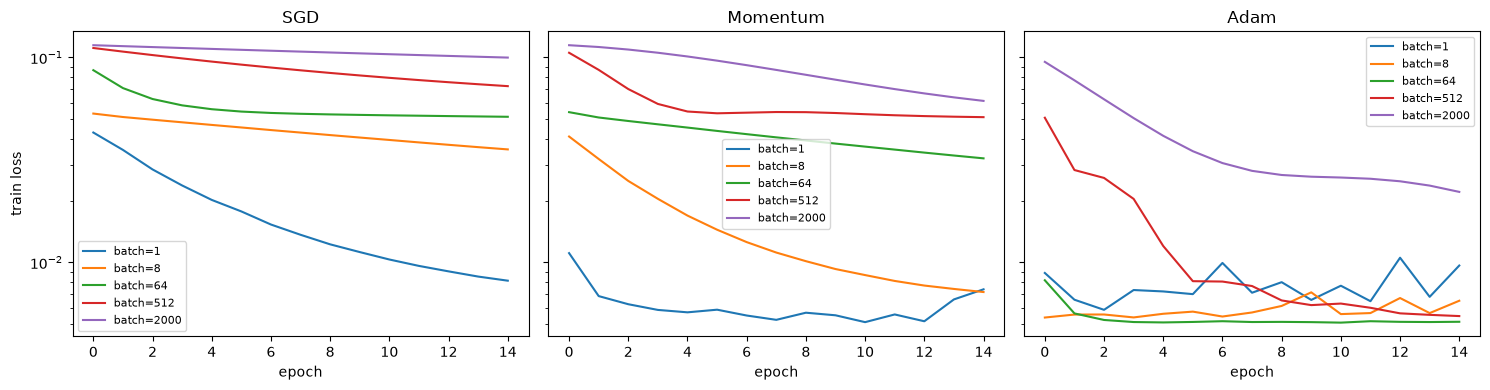

In [4]:
def run_grid(batches, builders):
    out = {}
    for b in batches:
        for name, builder in builders.items():
            opt = builder()
            _, h = train(model, opt, X_syn, y_syn, epochs=15, batch_size=b, init_w=init, seed=0)
            out[(name, b)] = h
    return out

batches = [1, 8, 64, 512, len(X_syn)]
builders = {
    'SGD': lambda: SGD(lr=0.01),
    'Momentum': lambda: Momentum(lr=0.01),
    'Adam': lambda: Adam(lr=0.05),
}
grid = run_grid(batches, builders)

with figure(ncols=3, figsize=(15, 4)) as axes:
    for ax in axes[1:]:
        ax.sharey(axes[0])
        ax.tick_params(labelleft=False)
    for ax, name in zip(axes, builders):
        for b in batches:
            ax.plot(grid[(name, b)].epoch_loss, label=f'batch={b}')
        ax.set_title(name)
        ax.set_xlabel('epoch')
        ax.set_yscale('log')
        ax.legend(fontsize=8)
    axes[0].set_ylabel('train loss')

In [5]:
rows = []
for (name, b), h in grid.items():
    rows.append({
        'method': name, 'batch': b, 'final_loss': h.epoch_loss[-1],
        'sec_per_epoch': float(np.mean(h.epoch_time_s)),
        'peak_mem_KB': h.peak_mem_bytes/1024,
        'opt_state_KB': h.opt_state_bytes/1024,
        'steps': h.n_steps,
    })
df_batch = pd.DataFrame(rows)
df_batch

,method,batch,final_loss,sec_per_epoch,peak_mem_KB,opt_state_KB,steps
0,SGD,1,0.008130,0.061822,377.911133,0.000000,30000
1,Momentum,1,0.007378,0.066927,377.101562,0.164062,30000
2,Adam,1,0.009641,0.112797,378.695312,0.328125,30000
3,SGD,8,0.035566,0.007768,378.625000,0.000000,3750
4,Momentum,8,0.007156,0.008680,378.898438,0.164062,3750
5,Adam,8,0.006489,0.014383,379.171875,0.328125,3750
6,SGD,64,0.051318,0.001087,379.937500,0.000000,480
7,Momentum,64,0.032162,0.001233,380.210938,0.164062,480
8,Adam,64,0.005123,0.001981,380.484375,0.328125,480
9,SGD,512,0.072416,0.000239,453.375000,0.000000,60


Заметим, что с маленьким батчем за эпоху делается больше шагов, поэтому по эпохам
сходимость быстрее, но по времени — сильно дороже: при `batch=1` эпоха идёт на два-три
порядка дольше, чем при полном батче. Adam к размеру батча заметно устойчивее, чем SGD.

По колонке `opt_state_KB` видно ровно то, что и ожидалось: SGD не хранит состояния,
Momentum хранит один буфер, Adam — два. От размера батча это не зависит.

А `peak_mem_KB` как память оптимизатора читать нельзя: это `tracemalloc` по всему прогону,
и в нём доминирует копия батча `X[idx]`. Поэтому число растёт вместе с батчем, а разницы
между SGD и Adam там не видно вовсе.


## 4. Расписания шага

Сравним постоянный, экспоненциальный и cosine-warmup на SGD/Adam.

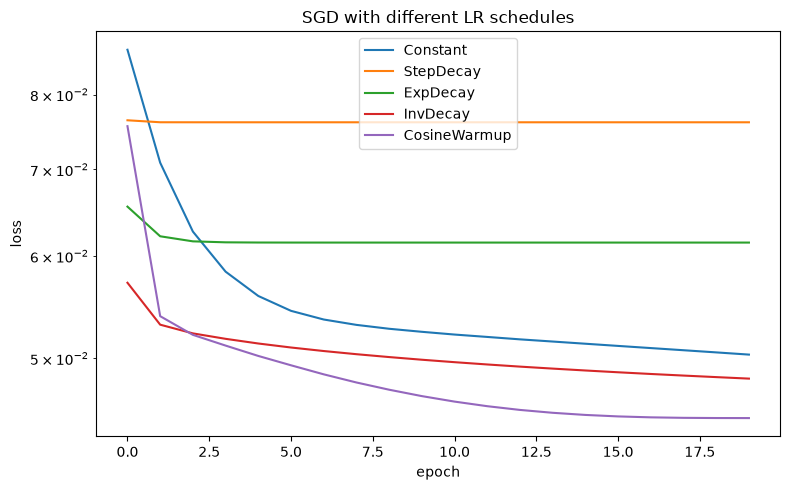

In [6]:
TOTAL = 20
scheds = {
    'Constant': ConstantLR(0.01),
    'StepDecay': StepDecay(0.05, step_size=5, gamma=0.5),
    'ExpDecay': ExpDecay(0.05, rate=0.05),
    'InvDecay': InvDecay(0.05, rate=0.01),
    'CosineWarmup': CosineWarmup(0.05, total=TOTAL*(len(X_syn)//64+1), warmup=50, lr_min=1e-4),
}
with figure(title='SGD with different LR schedules',
            xlabel='epoch', ylabel='loss', logy=True) as ax:
    for name, sch in scheds.items():
        opt = SGD(scheduler=sch)
        w, h = train(model, opt, X_syn, y_syn, epochs=TOTAL, batch_size=64, init_w=init, seed=0)
        ax.plot(h.epoch_loss, label=name)

Постоянный шаг быстрее всех застревает на шумовом полу — дальше он просто прыгает вокруг
минимума. Все убывающие расписания дают более гладкий хвост, лучше всех cosine-warmup.
У StepDecay на кривой видны ступеньки в эпохах, кратных `step_size`, а InvDecay убывает
медленнее экспоненциального и оказывается где-то посередине.


## 5. Влияние гиперпараметров

Отдельно от расписаний посмотрим на чувствительность методов к самим гиперпараметрам.
Главный из них — размер шага $\eta$. Прогоним лог-сетку $\eta \in [10^{-3}, 10]$
для SGD, Momentum и Adam при фиксированных батче 64 и 12 эпохах.


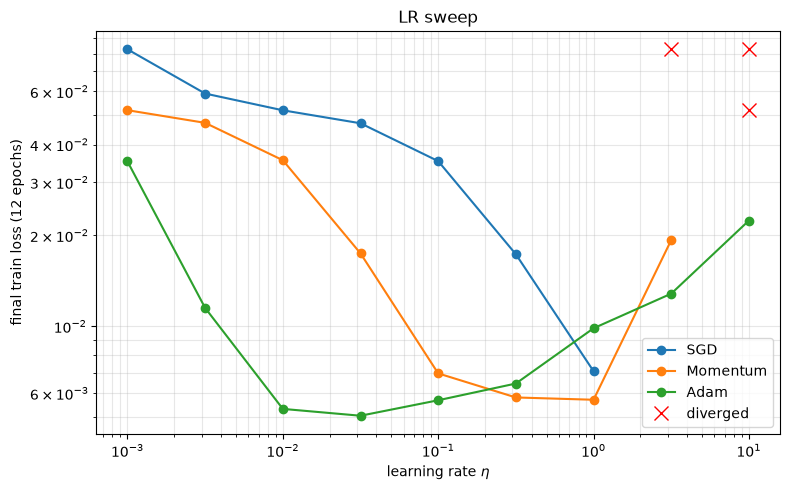

,SGD,Momentum,Adam
lr,,,
0.001,8.271741e-02,0.051983,0.035163
0.00316,5.902099e-02,0.047196,0.011496
0.01,5.194307e-02,0.035490,0.005322
0.0316,4.704677e-02,0.017432,0.005051
0.1,3.524619e-02,0.006977,0.005684
0.316,1.731412e-02,0.005807,0.006458
1,7.094794e-03,0.005706,0.009846
3.16,1.236545e+256,0.019298,0.012823
10,NaN,NaN,0.022399


In [7]:
lrs = np.logspace(-3, 1, 9)
sweep_classes = {'SGD': SGD, 'Momentum': Momentum, 'Adam': Adam}
lr_sweep = {}
for name, cls in sweep_classes.items():
    losses = []
    for lr in lrs:
        _, h = train(model, cls(lr=lr), X_syn, y_syn,
                     epochs=12, batch_size=64, init_w=init, seed=0)
        losses.append(h.epoch_loss[-1])
    lr_sweep[name] = np.array(losses, dtype=float)

with figure(xlabel=r'learning rate $\eta$',
            ylabel='final train loss (12 epochs)',
            title='LR sweep',
            logx=True, logy=True) as ax:
    diverged = []
    for name, losses in lr_sweep.items():
        ok = np.isfinite(losses) & (losses < 1e3)
        ax.plot(lrs[ok], losses[ok], 'o-', label=name)
        diverged += [(lr, np.nanmax(losses[ok])) for lr in lrs[~ok]]
    if diverged:
        ax.plot(*zip(*diverged), 'x', color='red', markersize=10, linestyle='none',
                label='diverged')
    ax.grid(True, which='both', alpha=0.3)

pd.DataFrame(lr_sweep, index=[f'{lr:.3g}' for lr in lrs]).rename_axis('lr')

Второй прогон — по коэффициенту момента $\beta$ у Momentum при фиксированном
$\eta = 0.01$.

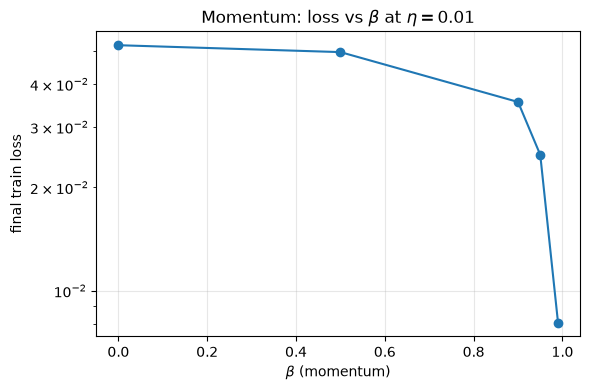

{0.0: 0.05194, 0.5: 0.04959, 0.9: 0.03549, 0.95: 0.0249, 0.99: 0.00807}


In [8]:
moms = [0.0, 0.5, 0.9, 0.95, 0.99]
mom_loss = []
for b in moms:
    _, h = train(model, Momentum(lr=0.01, momentum=b), X_syn, y_syn,
                 epochs=12, batch_size=64, init_w=init, seed=0)
    mom_loss.append(h.epoch_loss[-1])

with figure(xlabel=r'$\beta$ (momentum)', ylabel='final train loss',
            title=r'Momentum: loss vs $\beta$ at $\eta=0.01$',
            logy=True, figsize=(6, 4)) as ax:
    ax.plot(moms, mom_loss, 'o-')
    ax.grid(True, alpha=0.3)
print({b: round(v, 5) for b, v in zip(moms, mom_loss)})

Заметим, что у SGD рабочий диапазон шага узкий: до $\eta = 1$ он монотонно улучшается,
а уже на $\eta \approx 3$ расходится и дальше выдаёт `nan`. Momentum сдвигает картину
влево — тот же результат достигается примерно на порядок меньшим шагом, но и расходится он
тоже раньше по эффективному шагу.

Adam же не разваливается нигде на всём диапазоне: он делит шаг на $\sqrt{\hat v}$, поэтому
обновление почти не зависит от масштаба градиента. Это не значит, что шаг можно не
подбирать — оптимум у него всё-таки есть, около $\eta \approx 0.03$, — но расходимостью он
не наказывает.

По моменту $\beta$ зависимость монотонная: чем больше, тем лучше. Так вышло потому, что
$\eta = 0.01$ взят с большим запасом по устойчивости, и момент просто увеличивает
эффективный шаг.


## 6. Регуляризация: L1 / L2 / ElasticNet

Возьмём синтетику, где из 40 истинных весов ненулевых всего 5, а остальные 35 — ровно нули.
Тогда можно отдельно смотреть, что регуляризатор делает с «сигнальными» координатами и что —
с «шумовыми», которые он в идеале должен обнулить.


In [9]:
rng = np.random.default_rng(7)
d_sparse = 40
X_s = rng.standard_normal((1000, d_sparse))
w_sparse = np.zeros(d_sparse); idx = rng.choice(d_sparse, 5, replace=False); w_sparse[idx] = rng.standard_normal(5)*3
y_s = X_s @ w_sparse + 0.05 * rng.standard_normal(1000)

signal = np.zeros(d_sparse, dtype=bool); signal[idx] = True

regs = {'none': NoReg(), 'L2': L2(0.1), 'L1': L1(0.05), 'ElasticNet': ElasticNet(0.05, l1_ratio=0.7)}
rows, weights = [], {}
for name, R in regs.items():
    m = LinearRegressionModel(regularizer=R)
    init_s = m.init_params(d_sparse)
    w, h = train(m, Adam(lr=0.05), X_s, y_s, epochs=80, batch_size=64, init_w=init_s, seed=0)
    weights[name] = w[:-1]
    aw = np.abs(w[:-1])
    rows.append({
        'regularizer': name,
        'mse': float(LinearRegressionModel().loss(w, X_s, y_s)),
        'mean|w| signal': aw[signal].mean(),
        'mean|w| noise': aw[~signal].mean(),
        'noise/signal': aw[~signal].mean() / aw[signal].mean(),
        'exact zeros': int(np.sum(aw == 0.0)),
        '|w|<1e-3': int(np.sum(aw < 1e-3)),
    })
df_reg = pd.DataFrame(rows)
df_reg


,regularizer,mse,mean|w| signal,mean|w| noise,noise/signal,exact zeros,|w|<1e-3
0,none,0.001224,2.238643,0.002558,0.001143,0,9
1,L2,0.176193,2.038433,0.016678,0.008182,0,1
2,L1,0.007046,2.190741,0.002798,0.001277,0,7
3,ElasticNet,0.014829,2.171500,0.003863,0.001779,0,5


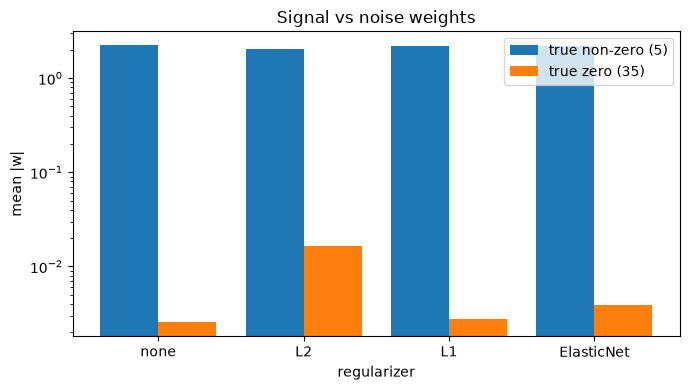

In [10]:
with figure(xlabel='regularizer', ylabel='mean |w|', logy=True,
            title='Signal vs noise weights', figsize=(7, 4)) as ax:
    names = df_reg['regularizer']
    pos = np.arange(len(names))
    ax.bar(pos - 0.2, df_reg['mean|w| signal'], width=0.4, label='true non-zero (5)')
    ax.bar(pos + 0.2, df_reg['mean|w| noise'], width=0.4, label='true zero (35)')
    ax.set_xticks(pos); ax.set_xticklabels(names)


Заметим, что точных нулей не получилось ни у одного регуляризатора — колонка `exact zeros`
везде нулевая.

Обычно про L1 говорят, что он зануляет часть координат, но это верно для точного минимума
задачи, а не для траектории метода. Субградиент $\lambda\,\mathrm{sign}(w_i)$ вблизи нуля
не затухает, поэтому координата перескакивает через нуль и меняет знак — и так и болтается
рядом с ним, никогда в него не попадая. Чтобы получить настоящие нули, нужен проксимальный
шаг (soft-thresholding), которого в реализации нет.

Зато хорошо видно другое. Сигнальные веса все четыре варианта восстанавливают примерно
одинаково, а вот шумовые различаются: у L1 и ElasticNet они порядка $3\cdot10^{-3}$, у L2
почти на порядок больше. То есть L1 давит лишние координаты сильнее L2, просто не до нуля.
На этих данных он при этом не лучше, чем вообще без регуляризации — шума мало и модель и так
почти точно попадает в истинные веса.

L2 с $\lambda = 0.1$ заодно заметно портит саму подгонку: ошибка у него на два порядка
хуже остальных. Колонка `mse` считается без штрафа, поэтому строки в ней сравнимы между собой.


## 7. Полиномиальная регрессия

Полиномиальная регрессия — **частный случай линейной**: нелинейность вносится не в
модель, а в признаки. Мономы $x, x^2, \dots, x^p$ (в многомерном случае — все
мономы степени $\le p$) вычисляются как новая матрица объект-признак $\Phi$, после чего
решается обычная задача МНК $\min_w \|\Phi w - y\|^2$, линейная по $w$. Поэтому
никаких изменений в оптимизаторах не требуется — тот же `train()`, те же методы.

Реализация — `src/models/poly.py`: `polynomial_features(X, degree)` строит мономы через
`combinations_with_replacement`, а `PolynomialRegression` наследует
`LinearRegressionModel`, переопределяя только `predict/loss/grad` через `transform`.

Данные мы взяли одномерные, с кубической зависимостью
$y = 0.5x^3 - 1.5x^2 + 2x + 1 + \xi$. **Признак $x$ предварительно стандартизован** —
у мономов разных степеней сильно разный масштаб, и без этого обусловленность
$\Phi^\top\Phi$ портится настолько, что методы первого порядка сходятся неубедительно.


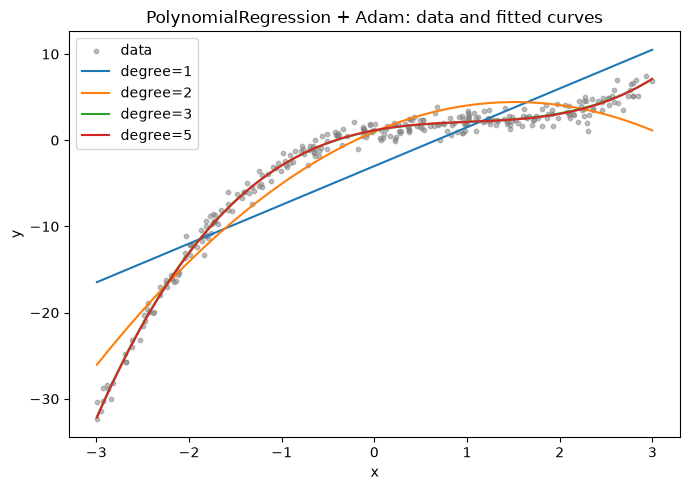

,degree,n_params,final_loss,opt_state_KB
0,1,2,9.269882,0.031250
1,2,3,2.124441,0.046875
2,3,4,0.312023,0.062500
3,5,6,0.312813,0.093750


In [11]:
rng_p = np.random.default_rng(3)
x_raw = np.sort(rng_p.uniform(-3, 3, 300))
y_poly = 0.5*x_raw**3 - 1.5*x_raw**2 + 2*x_raw + 1 + 0.8*rng_p.standard_normal(300)
X_poly = ((x_raw - x_raw.mean()) / x_raw.std()).reshape(-1, 1)

rows_p = []
with figure(xlabel='x', ylabel='y', figsize=(7, 5),
            title='PolynomialRegression + Adam: data and fitted curves') as ax:
    ax.scatter(x_raw, y_poly, s=10, alpha=0.5, color='gray', label='data')
    for deg in [1, 2, 3, 5]:
        pm = PolynomialRegression(degree=deg)
        w_p, h_p = train(pm, Adam(lr=0.05), X_poly, y_poly,
                         epochs=150, batch_size=32, init_w=pm.init_params(deg), seed=0)
        ax.plot(x_raw, pm.predict(w_p, X_poly), label=f'degree={deg}')
        rows_p.append({'degree': deg, 'n_params': len(w_p),
                       'final_loss': h_p.epoch_loss[-1],
                       'opt_state_KB': h_p.opt_state_bytes/1024})

pd.DataFrame(rows_p)

Прямая и парабола ожидаемо недообучены — кубическую форму они просто не могут
воспроизвести. Начиная с degree=3 кривая ложится на данные, а loss упирается в шумовой
предел, ниже которого спуститься нельзя. Degree=5 ничего не улучшает: лишние мономы только
добавляют параметров, что видно и по росту `opt_state_KB`.


## 8. Линии уровня и траектории 

Двумерная задача — рисуем линии уровня MSE-функции и накладываем траектории нескольких методов.

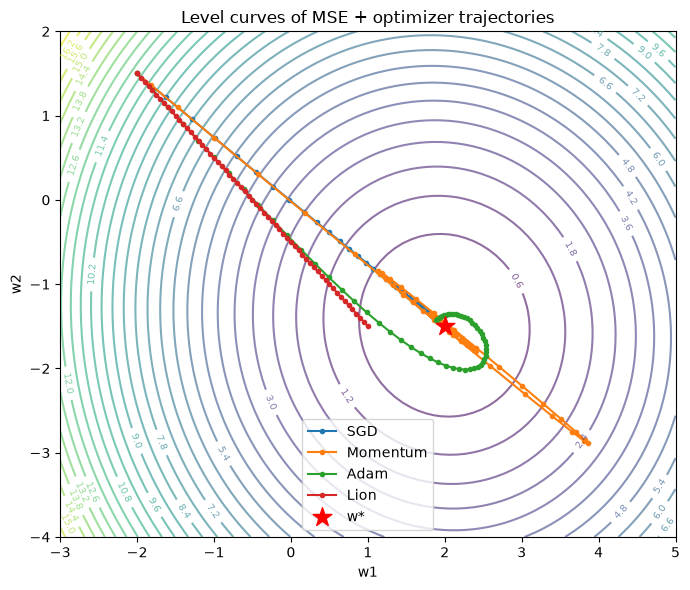

In [12]:
rng = np.random.default_rng(0)
X2 = rng.standard_normal((200, 2)); w_star = np.array([2.0, -1.5])
y2 = X2 @ w_star + 0.1 * rng.standard_normal(200)
model2 = LinearRegressionModel(fit_intercept=False)

def loss_surface(w):
    return 0.5 * np.mean((X2 @ w - y2)**2)

init2 = np.array([-2.0, 1.5])
methods = {
    'SGD':      SGD(lr=0.1),
    'Momentum': Momentum(lr=0.05),
    'Adam':     Adam(lr=0.2),
    'Lion':     Lion(lr=0.05),
}
trajs = {}
for name, opt in methods.items():
    w = init2.copy(); opt.reset(); traj = [w.copy()]
    for _ in range(60):
        g = model2.grad(w, X2, y2)
        w = opt.step(w, g)
        traj.append(w.copy())
    trajs[name] = np.array(traj)

plot_contours(loss_surface, xlim=(-3, 5), ylim=(-4, 2),
              trajectories=trajs, optimum=w_star,
              title='Level curves of MSE + optimizer trajectories',
              xlabel='w1', ylabel='w2', figsize=(7, 6))

## 9. Сравниваем на реальном датасете

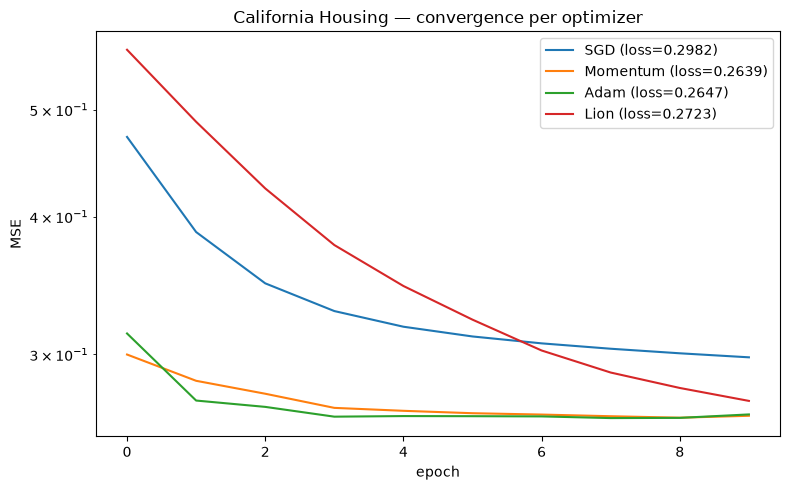

In [13]:
m_cal = LinearRegressionModel(regularizer=L2(1e-4))
init_cal = m_cal.init_params(X_cal.shape[1])
methods = [SGD(lr=0.005), Momentum(lr=0.005), Adam(lr=0.01), Lion(lr=0.001)]
with figure(title='California Housing — convergence per optimizer',
            xlabel='epoch', ylabel='MSE', logy=True) as ax:
    for opt in methods:
        w, h = train(m_cal, opt, X_cal, y_cal, epochs=10, batch_size=256,
                     init_w=init_cal, seed=0)
        ax.plot(h.epoch_loss, label=f'{opt.name} (loss={h.epoch_loss[-1]:.4f})')

## 10. Extension-1: своя реализация Lion

Шаг Lion — это
$\Delta w = -\eta \cdot \mathrm{sign}\big(\beta_1 m_{t-1} + (1-\beta_1) g_t\big) - \eta\,\lambda w$,
после чего буфер обновляется как $m_t = \beta_2 m_{t-1} + (1-\beta_2) g_t$. Коэффициентов
момента два и они независимы: $\beta_1$ отвечает за направление шага, $\beta_2$ — за то,
что копится в буфере.

Отсюда три следствия. Буфер хранится один (против двух у Adam), то есть памяти нужно вдвое
меньше. Каждый шаг по модулю равен $\eta$ покоординатно, поэтому шаг нужен меньше, чем у
Adam — обычно в 3–10 раз.

Реализация: `src/optimizers/lion.py`. Сравним с собственным Adam и с `torch.optim.AdamW`
на той же синтетике.


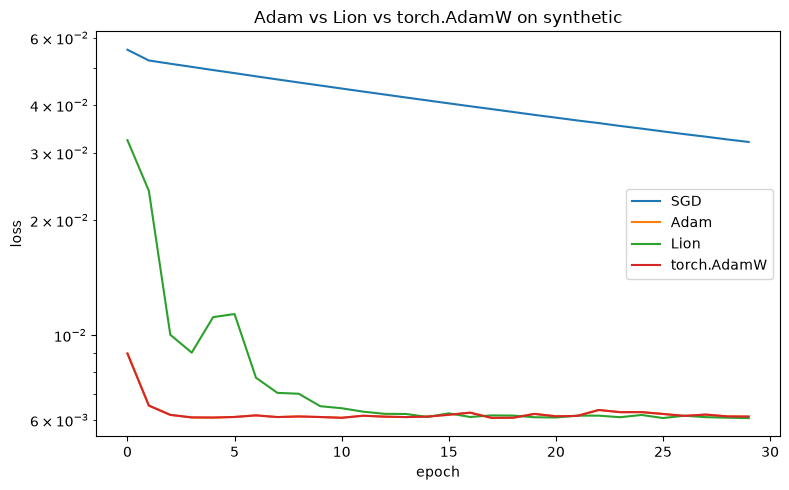

,method,n_params,opt_state_bytes,buffers_per_param,final_loss
0,SGD,21,0,0.0,0.032039
1,Adam,21,336,2.0,0.006124
2,Lion,21,168,1.0,0.006068
3,torch.AdamW,21,0,0.0,0.006124


In [14]:
m = LinearRegressionModel(regularizer=L2(1e-4))
init_l = m.init_params(X_syn.shape[1])
opts = [SGD(lr=0.05), Adam(lr=0.05), Lion(lr=0.01, weight_decay=1e-4),
        TorchAdamW(lr=0.05, weight_decay=1e-4)]
mem_rows = []
with figure(title='Adam vs Lion vs torch.AdamW on synthetic',
            xlabel='epoch', ylabel='loss', logy=True) as ax:
    for opt in opts:
        w, h = train(m, opt, X_syn, y_syn, epochs=30, batch_size=64,
                     init_w=init_l, seed=0)
        ax.plot(h.epoch_loss, label=f'{opt.name}')
        mem_rows.append({'method': opt.name, 'n_params': len(w),
                         'opt_state_bytes': h.opt_state_bytes,
                         'buffers_per_param': h.opt_state_bytes/(8*len(w)),
                         'final_loss': h.epoch_loss[-1]})

pd.DataFrame(mem_rows)

Заметим, что измеренная память подтверждает главное обещание Lion: он хранит один буфер
момента против двух у Adam, то есть вдвое меньше. Качество при этом сравнимое.


## 11. Extension-2: задача SVM (soft-margin) с точки зрения оптимизации

Для линейно неразделимых данных классическая SVM формулируется как выпуклая задача:
$$\min_{w, b}\;\; \tfrac{1}{2}\|w\|^2 + C \cdot \frac{1}{n}\sum_i \max\!\big(0,\;1 - y_i(w^\top x_i + b)\big),
\quad y_i \in \{-1,+1\}.$$

Функция потерь hinge не дифференцируема в точке $y_i s_i = 1$, но выпуклый, поэтому у него есть
субградиент:
$$\nabla_w \approx w + C \cdot \frac{1}{n}\sum_{i:\;y_i s_i < 1} (-y_i x_i),$$


In [15]:
from sklearn.datasets import make_classification
from sklearn.svm import LinearSVC

from svm.soft_margin import SoftMarginSVM

Xc, yc = make_classification(n_samples=400, n_features=2, n_redundant=0, n_informative=2,
                              n_clusters_per_class=1, class_sep=1.4, random_state=0)
yc = np.where(yc == 0, -1, 1).astype(float)

svm = SoftMarginSVM(C=1.0)
init_svm = svm.init_params(2)
results = {}
for opt in [SGD(lr=0.01), Adam(lr=0.05), Lion(lr=0.005)]:
    p, h = train(svm, opt, Xc, yc, epochs=40, batch_size=32, init_w=init_svm, seed=0)
    results[opt.name] = (p, h)

ref = LinearSVC(C=1.0, loss='hinge', max_iter=10000).fit(Xc, yc)
print('sklearn LinearSVC acc =', ref.score(Xc, yc))
for name, (p, h) in results.items():
    pred = svm.predict(p, Xc)
    print(f'{name:8s}  loss={h.epoch_loss[-1]:.4f}  acc={(pred==yc).mean():.3f}')


sklearn LinearSVC acc = 0.9325
SGD       loss=0.5140  acc=0.915
Adam      loss=0.5162  acc=0.917
Lion      loss=0.5139  acc=0.920


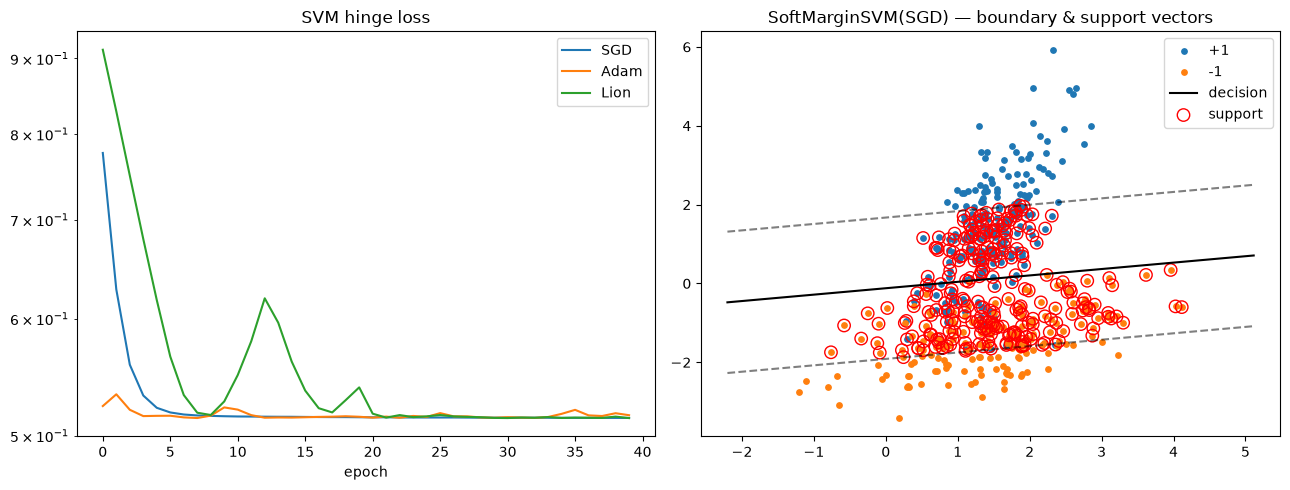

In [16]:
with figure(ncols=2, figsize=(13, 5)) as axes:
    for name, (p, h) in results.items():
        axes[0].plot(h.epoch_loss, label=name)
    axes[0].set_yscale('log')
    axes[0].set_title('SVM hinge loss')
    axes[0].set_xlabel('epoch')

    ax = axes[1]
    ax.scatter(Xc[yc==1, 0], Xc[yc==1, 1], c='tab:blue', s=15, label='+1')
    ax.scatter(Xc[yc==-1, 0], Xc[yc==-1, 1], c='tab:orange', s=15, label='-1')
    p_best = results['SGD'][0]
    w_svm, b_svm = p_best[:-1], p_best[-1]
    xx = np.linspace(Xc[:,0].min()-1, Xc[:,0].max()+1, 100)
    yy = -(w_svm[0] * xx + b_svm) / w_svm[1]
    ax.plot(xx, yy, 'k-', label='decision')
    ax.plot(xx, yy + 1/w_svm[1], 'k--', alpha=0.5)
    ax.plot(xx, yy - 1/w_svm[1], 'k--', alpha=0.5)
    support = (yc * (Xc @ w_svm + b_svm) < 1)
    ax.scatter(Xc[support, 0], Xc[support, 1], facecolors='none',
               edgecolors='red', s=80, label='support')
    ax.set_title('SoftMarginSVM(SGD) — boundary & support vectors')

## 12. Extension-3: три способа вычисления градиента

Реализованы:

1. **Численное дифференцирование** через центральные разности
   $\nabla_i f \approx \dfrac{f(x+\varepsilon e_i) - f(x-\varepsilon e_i)}{2\varepsilon}$.
   $O(d)$ вычислений $f$, точность зависит от шага $\varepsilon$ — см. 12.1.
2. **Forward-mode autodiff** через дуальные числа $a + b\,\varepsilon$ с
   $\varepsilon^2=0$. Перегружены `+ - * / **`, `exp`, `log`, `sqrt`. Тоже $O(d)$
   проходов.
3. **Reverse-mode** — `torch.autograd`. Один прямой и один обратный проход, то есть $O(1)$
   проходов независимо от $d$.


### 12.1 Точность численного дифференцирования от $\varepsilon$

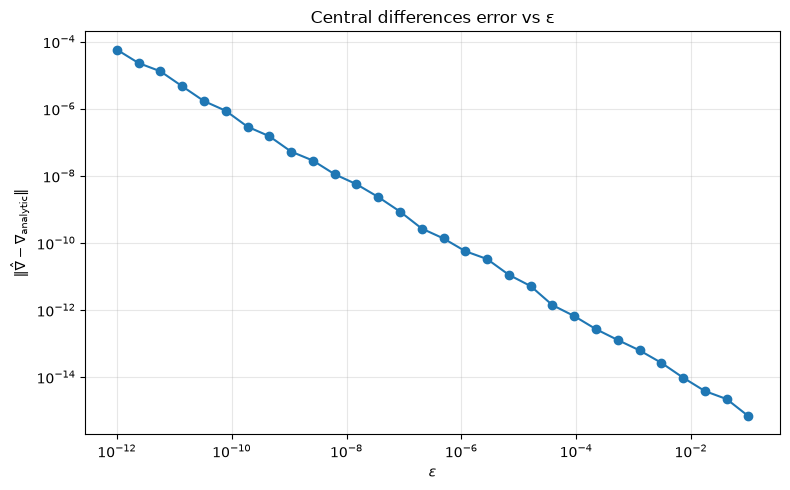

minimum error at eps=1.0e-01, err=6.79e-16


In [17]:
from autodiff.benchmark import analytic_mse_grad, mse_loss_dual, mse_loss_numpy
from autodiff.forward import forward_grad
from autodiff.numeric import epsilon_sweep

Xa = X_syn[:50]; ya = y_syn[:50]
w0 = np.random.default_rng(0).standard_normal(Xa.shape[1])
g_a = analytic_mse_grad(Xa, ya, w0)

epss = np.logspace(-12, -1, 30)
errs = epsilon_sweep(mse_loss_numpy(Xa, ya), w0, g_a, epss)

with figure(xlabel=r'$\varepsilon$',
            ylabel=r'$\|\hat\nabla - \nabla_{\rm analytic}\|$',
            title='Central differences error vs ε',
            logx=True, logy=True) as ax:
    ax.plot(epss, errs, 'o-')
    ax.grid(True, which='both', alpha=0.3)
print(f'minimum error at eps={epss[errs.argmin()]:.1e}, err={errs.min():.2e}')

U-образной кривой здесь не получилось: ошибка монотонно убывает по всему диапазону.
Обычно она складывается из ошибки усечения (растёт с $\varepsilon$) и ошибки округления
(падает с $\varepsilon$), и их баланс даёт минимум где-то посередине. Но у нас функция
потерь — MSE, то есть квадратичная, у неё $f'''\equiv 0$, и ошибка усечения тождественно
нулевая. Остаётся только округление, которое с ростом шага монотонно убывает.

### 12.2 Совпадение forward-AD с аналитическим градиентом

In [18]:
g_f = forward_grad(mse_loss_dual(Xa, ya), w0)
print('||forward - analytic|| =', np.linalg.norm(g_f - g_a))


||forward - analytic|| = 1.1799387734598425e-17


### 12.3 Время вычисления градиента vs размерность $d$

Меряем для MSE-функции потерь из базового задания, варьируя $d \in [10,1000]$.

d=  10  numeric=   0.08 ms  forward=   8.30 ms  reverse=   0.22 ms
d=  30  numeric=   0.18 ms  forward=  70.22 ms  reverse=   0.13 ms


d= 100  numeric=   0.55 ms  forward= 756.58 ms  reverse=   0.13 ms


d= 300  numeric=   2.03 ms  forward=6867.54 ms  reverse=   0.24 ms
d=1000  numeric=  17.78 ms  forward=    nan ms  reverse=   0.20 ms


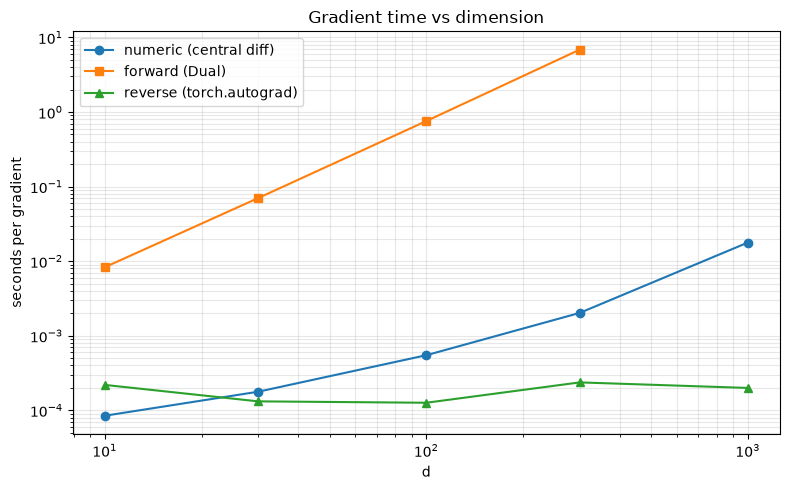

In [19]:
from autodiff.benchmark import time_forward, time_numeric, time_reverse_torch

ds = [10, 30, 100, 300, 1000]
n_fixed = 50
t_num, t_fwd, t_rev = [], [], []
for d in ds:
    rng = np.random.default_rng(d)
    X = rng.standard_normal((n_fixed, d)); y = rng.standard_normal(n_fixed)
    w = rng.standard_normal(d)
    tn, _ = time_numeric(X, y, w, eps=1e-6)
    tf, _ = time_forward(X, y, w) if d <= 300 else (np.nan, None)
    tr, _ = time_reverse_torch(X, y, w, repeat=5)
    t_num.append(tn); t_fwd.append(tf); t_rev.append(tr)
    print(f'd={d:4d}  numeric={tn*1e3:7.2f} ms  forward={tf*1e3 if tf==tf else float("nan"):7.2f} ms  reverse={tr*1e3:7.2f} ms')

with figure(xlabel='d', ylabel='seconds per gradient',
            title='Gradient time vs dimension', logx=True, logy=True) as ax:
    ax.plot(ds, t_num, 'o-', label='numeric (central diff)')
    ax.plot(ds, t_fwd, 's-', label='forward (Dual)')
    ax.plot(ds, t_rev, '^-', label='reverse (torch.autograd)')
    ax.grid(True, which='both', alpha=0.3)

Численный способ и forward-AD оба требуют $O(d)$ проходов, поэтому обе кривые растут
быстро. Forward при этом заметно медленнее: он написан на чистом Python с поэлементным
циклом, и не векторизован.

Reverse-mode — один прямой и один обратный проход независимо от $d$, поэтому на больших
размерностях он работает быстрее.


## 13. Выводы

1. Все шесть собственных реализаций совпадают с `torch.optim` до машинной точности, но
   только если выровнены все гиперпараметры, включая `eps`.

2. Маленький батч даёт более быструю сходимость по эпохам, но заметно проигрывает по
   времени; полный батч идёт гладко, но медленно. Adam к выбору батча менее чувствителен,
   чем SGD.

3. Памяти оптимизаторы едят ровно столько, сколько следует из формул: SGD — нисколько,
   Momentum и остальные — один буфер, Adam — два.

4. У SGD и Momentum шаг приходится подбирать аккуратно: чуть больше нужного — и метод
   расходится. Adam на всём диапазоне остаётся конечным, хотя оптимум у него тоже есть.

5. Из расписаний лучший хвост даёт cosine-warmup, постоянный шаг застревает на шумовом
   полу раньше всех.

6. L1 и ElasticNet сжимают лишние веса сильнее L2, но точных нулей не дают — для этого
   нужен проксимальный шаг, которого в реализации нет.

7. Lion хранит один буфер вместо двух у Adam при сравнимом качестве, но требует
   меньшего шага.

8. SVM с hinge loss решается тем же субградиентным SGD и по точности немного
   уступает `LinearSVC`.

9. Из трёх способов считать градиент численный проще всего, но зависит от выбора
   $\varepsilon$; forward-AD точен, но требует $O(d)$ проходов; reverse-mode обходится
   одним проходом и единственный годится для больших $d$.

10. Полиномиальная регрессия сводится к линейной расширением признаков — те же
    оптимизаторы без изменений восстанавливают кубическую зависимость.
